# Logistic Regression: scikit-learn on Breast Cancer, then From Scratch

**Part 1** trains a scikit-learn logistic regression on the Wisconsin breast-cancer dataset with a leak-free protocol: stratified split, scaling inside a pipeline, a majority-class baseline, and cross-validated scores with uncertainty.
**Part 2** implements logistic regression with NumPy gradient descent on a toy 2-D dataset and checks it against scikit-learn on held-out data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             make_scorer, recall_score, roc_auc_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

# Part 1: Logistic Regression on the Breast Cancer Dataset


In this tutorial, we'll use **Logistic Regression** to classify whether a tumor is **malignant (cancerous)** or **benign (non-cancerous)** using real-world medical data.

We'll use the built-in **Breast Cancer Wisconsin Dataset** from `sklearn.datasets`.

This is a binary classification problem — making it perfect for Logistic Regression.


In [2]:
# Load dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Check shapes
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (569, 30)
Target shape: (569,)


In [3]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
y.head()

0    0
1    0
2    0
3    0
4    0
dtype: int64

## Dataset Overview

- **Samples**: 569
- **Features**: 30 (numerical measurements like radius, texture, area, smoothness etc.)
- **Target**:
  - 0 → Malignant
  - 1 → Benign

Let’s explore the data before modeling.


In [5]:
print("Target class distribution:")
y.value_counts()

Target class distribution:


1    357
0    212
Name: count, dtype: int64

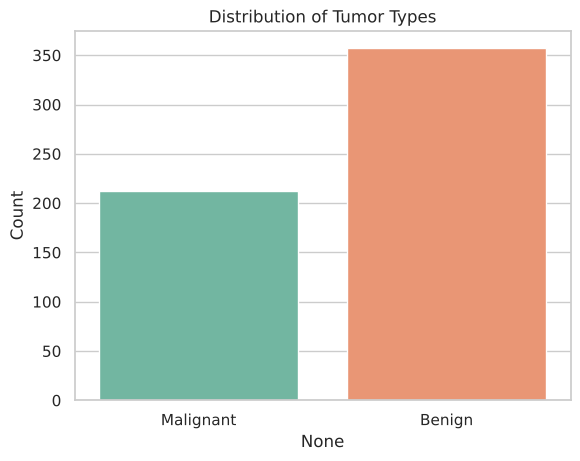

In [6]:
sns.countplot(x=y.map({0: "Malignant", 1: "Benign"}), hue=y.map({0: "Malignant", 1: "Benign"}),
              palette='Set2', legend=False)
plt.title("Distribution of Tumor Types")
plt.ylabel("Count")
plt.show()

## Train-test split and baseline

The split is **stratified** (class ratio is 37 % / 63 %, so a random split could shift it). Scaling is **not** done here: it goes inside a `Pipeline` below, so the scaler only ever sees training data, including inside cross-validation.

A majority-class baseline is reported first: on this dataset it already scores ~63 % accuracy, so accuracy alone is a weak yardstick. For a cancer screen, **recall on the malignant class** (missed cancers) and ROC-AUC matter more.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f"Majority-class baseline accuracy (test): {baseline.score(X_test, y_test):.3f}")

Majority-class baseline accuracy (test): 0.632


## Train Logistic Regression

`StandardScaler` + `LogisticRegression` in one pipeline. Logistic regression with regularisation is sensitive to feature scale, so scaling is needed, and the pipeline fits it on training data only.

In [8]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Model Evaluation

First, repeated stratified 5-fold cross-validation on the **training set** (mean ± std over 25 fits). Then one evaluation on the untouched test set.

In [9]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
scoring = {'accuracy': 'accuracy',
           'recall_malignant': make_scorer(recall_score, pos_label=0),   # malignant = label 0
           'roc_auc': 'roc_auc'}

rows = {}
for name, est in {'majority baseline': DummyClassifier(strategy='most_frequent'), 'logistic regression': model}.items():
    res = cross_validate(est, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {m: f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}" for m in scoring}
pd.DataFrame(rows).T

,accuracy,recall_malignant,roc_auc
majority baseline,0.626 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
logistic regression,0.980 ± 0.011,0.964 ± 0.025,0.995 ± 0.006


In [10]:
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}   ROC-AUC: {roc_auc_score(y_test, y_score):.4f}   "
      f"malignant recall: {recall_score(y_test, y_pred, pos_label=0):.4f}")
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Classification Report:\n", classification_report(y_test, y_pred, target_names=["Malignant", "Benign"]))

Test accuracy: 0.9825   ROC-AUC: 0.9954   malignant recall: 0.9762
Confusion Matrix:
 [[41  1]
 [ 1 71]]
Classification Report:
               precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



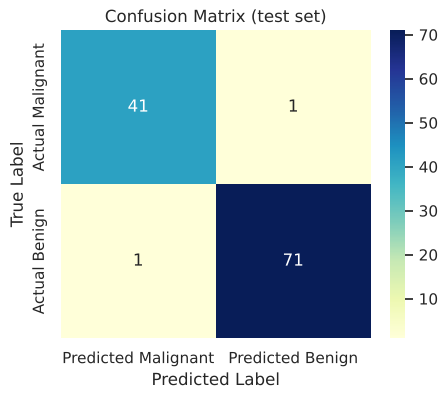

In [11]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=["Predicted Malignant", "Predicted Benign"],
            yticklabels=["Actual Malignant", "Actual Benign"])
plt.title("Confusion Matrix (test set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

**Interpretation.** The 114-row test set means one patient is ~0.9 percentage points, so differences of a point or two are not meaningful; the cross-validated ± std is the better guide. Every misclassified malignant case is a missed diagnosis, so a real screening system would tune the decision threshold for recall rather than accept 0.5.

# Part 2: Logistic Regression From Scratch


**What Is Logistic Regression?**

**Logistic Regression** is a supervised machine learning algorithm used for **binary classification**.

It models the **probability** that a given input belongs to class 1 (positive class), using a logistic (sigmoid) function to ensure the output lies between 0 and 1.

---
**Why Not Linear Regression for Classification?**

In Linear Regression, we model:

$$
\hat{y} = w_1 x_1 + w_2 x_2 + b
$$

This works for predicting continuous outputs — but:
- It can produce values **less than 0** or **greater than 1**
- There's **no probabilistic interpretation**
- It doesn't handle **classification boundaries**

Hence, Linear Regression is **not suitable** for classification tasks.

---

**Why Logistic Regression?**

We fix these problems by applying the **sigmoid function** to the linear combination:

$$
z = w_1 x_1 + w_2 x_2 + b
\quad \Rightarrow \quad
\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

- Output $ \hat{y} $ is always between 0 and 1  
- Interpretable as a **probability** of belonging to class 1  
- Classification decision is made by thresholding:  
  If $ \hat{y} \geq 0.5 $, predict class 1; else class 0

---

**Can Logistic Regression Be Used for Regression?**

Despite its name, **Logistic Regression is *not* used for regression tasks**.  
It is fundamentally a **classification algorithm**, its goal is to **separate categories**, not estimate continuous values.

---
The main objective is to Learn parameters $ w_1, w_2, b $ using **Gradient Descent**, minimizing the **Log Loss (Binary Cross-Entropy)**:

$$
J(w, b) = -\frac{1}{n} \sum_{i=1}^n \left[y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i)\right]
$$

## Generate a Toy Binary Classification Dataset

A clean, 2-D dataset from `make_classification`. It gets its own variable names (`X_toy`, `y_toy`) so Part 1's data is not overwritten, and it is split into train and test so the from-scratch model is also judged on unseen points. Features are standardised using training statistics only, which makes gradient descent well behaved.

In [12]:
X_toy, y_toy = make_classification(n_samples=200, n_features=2, n_redundant=0,
                                   n_informative=2, n_clusters_per_class=1, random_state=42)
Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_toy, y_toy, test_size=0.25, random_state=42, stratify=y_toy
)
sc = StandardScaler().fit(Xt_train)
Xt_train, Xt_test = sc.transform(Xt_train), sc.transform(Xt_test)

df = pd.DataFrame(Xt_train, columns=['x1', 'x2'])
df['y'] = yt_train
df.head()

,x1,x2,y
0,-0.533822,-0.700051,0
1,1.054127,-0.399307,1
2,0.269272,-0.765303,1
3,0.243346,-0.217097,0
4,0.831067,1.636154,1


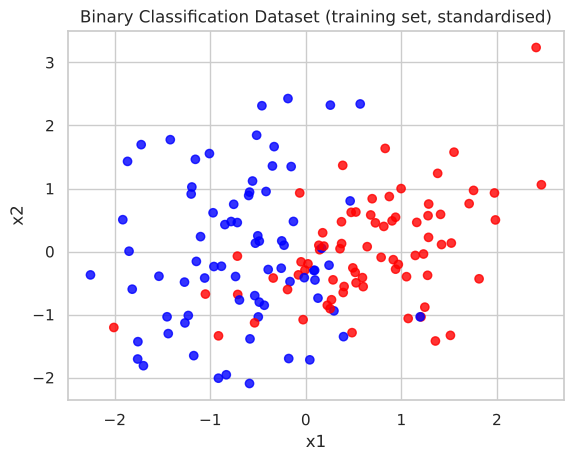

In [13]:
plt.scatter(Xt_train[:, 0], Xt_train[:, 1], c=yt_train, cmap='bwr', alpha=0.8)
plt.title("Binary Classification Dataset (training set, standardised)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## Initialize Parameters and Define Helper Functions

We now define key components of the Logistic Regression algorithm:

---

**Sigmoid Function**

This function transforms any real-valued input into a value between 0 and 1.

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Where:

- $ z = w_1 x_1 + w_2 x_2 + b $
- Output $ \hat{y} = \sigma(z) \in (0, 1) $
- Interpreted as **probability** of class 1

---

**Prediction Function**

To compute predictions:

- Compute $ z = X \cdot w + b $
- Apply sigmoid to get probabilities $ \hat{y} $

$$
\hat{y} = \sigma(w_1 x_1 + w_2 x_2 + b)
$$

We can threshold $ \hat{y} $ at 0.5 to make final predictions:

$$
\text{predict class 1 if } \hat{y} \geq 0.5
$$

---

**Binary Cross-Entropy Loss (Log Loss)**

This is the cost function we want to **minimize**:

$$
J(w, b) = -\frac{1}{n} \sum_{i=1}^n \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]
$$

- Penalizes **wrong confident predictions** heavily
- Encourages the model to output probabilities close to true labels

---

We now implement all of this in code.

In [14]:
# Sigmoid activation
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Prediction
def predict_proba(X, w, b):
    return sigmoid(np.dot(X, w) + b)

def predict(X, w, b, threshold=0.5):
    return (predict_proba(X, w, b) >= threshold).astype(int)

# Binary Cross-Entropy Loss
def log_loss(y_true, y_prob):
    epsilon = 1e-15
    y_prob = np.clip(y_prob, epsilon, 1 - epsilon)
    return -np.mean(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))

## Train Using Gradient Descent
---

**Why Do We Use Gradient Descent?**

In Logistic Regression, we want to find the best parameters $w_1, w_2, b$ such that the model's predicted probabilities match the actual labels $y$.

---

**Why Not Closed-Form Like in Linear Regression?**

Linear regression has a closed-form solution (the normal equations) because setting the gradient of its squared-error loss to zero gives a *linear* system. For logistic regression the loss is **convex** (so there is a single global minimum and gradient descent is guaranteed to find it for a small enough step size), but the gradient equations contain the sigmoid, so they are *non-linear* in $w$ and cannot be solved directly. We solve them iteratively.

---

**Why Gradient Descent?**

Gradient Descent is an **iterative optimization algorithm** that:

- Starts with **random parameter values**
- Computes the **gradient (slope)** of the loss function
- Updates parameters in the **direction of steepest descent** (i.e., opposite to the gradient)

This continues until we reach the **minimum of the loss function**, ideally where the model is making the best predictions.

---

**How Gradient Descent Works**

At each step:
1. Compute predictions: $\hat{y} = \sigma(w_1 x_1 + w_2 x_2 + b)$  
2. Compute the log loss between $\hat{y}$ and $y$  
3. Compute gradients:

$$
\frac{\partial J}{\partial w_j} = \frac{1}{n} \sum_{i=1}^n (\hat{y}_i - y_i) \cdot x_{ij}
\qquad
\frac{\partial J}{\partial b} = \frac{1}{n} \sum_{i=1}^n (\hat{y}_i - y_i)
$$

4. Update weights and bias:

$$
w_j = w_j - \alpha \cdot \frac{\partial J}{\partial w_j}
\qquad
b = b - \alpha \cdot \frac{\partial J}{\partial b}
$$

Where:
- $\alpha$ is the learning rate
- The gradients point in the direction **we should not go** — so we subtract them to minimize loss

---

In [15]:
def train_logistic_regression(X, y, lr=0.1, epochs=1000, seed=1, verbose=True):
    rng = np.random.default_rng(seed)           # seeded, so results are reproducible
    n_samples, n_features = X.shape
    w = rng.normal(size=n_features)
    b = 0.0
    loss_history = []

    for epoch in range(epochs):
        y_prob = sigmoid(np.dot(X, w) + b)
        error = y_prob - y

        dw = (1 / n_samples) * np.dot(X.T, error)
        db = (1 / n_samples) * np.sum(error)

        w -= lr * dw
        b -= lr * db

        loss_history.append(log_loss(y, y_prob))   # loss before this epoch's update

        if verbose and epoch % 200 == 0:
            print(f"Epoch {epoch}: Loss = {loss_history[-1]:.4f}, w = {w}, b = {b:.4f}")

    return w, b, loss_history

In [16]:
w, b, loss_history = train_logistic_regression(Xt_train, yt_train, lr=0.1, epochs=1000)

Epoch 0: Loss = 0.6723, w = [0.36899055 0.80389653], b = 0.0002
Epoch 200: Loss = 0.3940, w = [ 1.97691649 -0.24789392], b = 0.0006
Epoch 400: Loss = 0.3856, w = [ 2.34567991 -0.37112277], b = -0.0064
Epoch 600: Loss = 0.3844, w = [ 2.48942422 -0.41038591], b = -0.0099
Epoch 800: Loss = 0.3842, w = [ 2.55216868 -0.42662084], b = -0.0114


## Make Predictions

Probabilities are $\hat{y}_i = \sigma(w_1 x_{i1} + w_2 x_{i2} + b)$; labels come from thresholding at 0.5. Shown for the first rows of the **test** set.

In [17]:
y_probs = predict_proba(Xt_test, w, b)
y_pred = (y_probs >= 0.5).astype(int)

results = pd.DataFrame({
    'x1': Xt_test[:, 0],
    'x2': Xt_test[:, 1],
    'True Label': yt_test,
    'Predicted Prob': y_probs.round(3),
    'Predicted Label': y_pred
})
results.head()

,x1,x2,True Label,Predicted Prob,Predicted Label
0,1.545650,1.309543,1,0.968,1
1,0.688599,0.304382,1,0.837,1
2,0.412443,-0.573243,1,0.786,1
3,-0.328857,0.496231,0,0.254,0
4,-1.310857,-1.045972,0,0.050,0


## Visualize Loss Curve

We now plot how the log loss reduces over epochs.


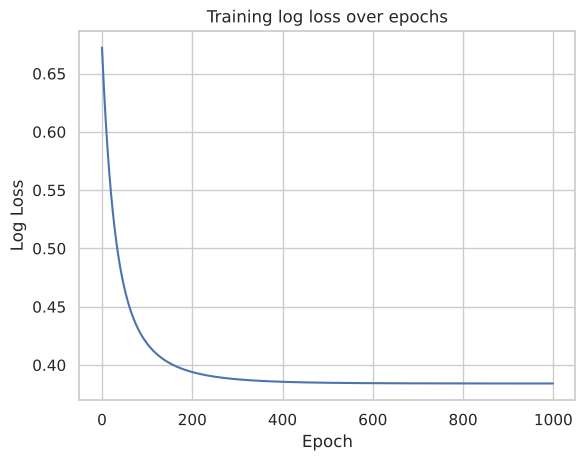

In [18]:
plt.plot(loss_history)
plt.title("Training log loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Log Loss")
plt.show()

### Decision boundary

We'll visualize the line where:

$$
w_1 x_1 + w_2 x_2 + b = 0 \Rightarrow \hat{y} = 0.5
$$

This separates class 0 from class 1.

Shown on the test points.

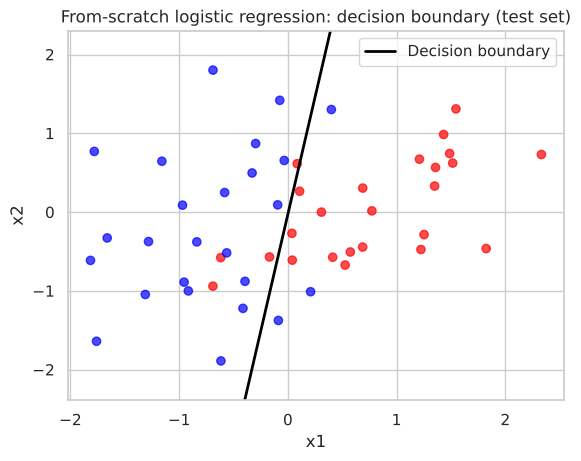

In [19]:
# Decision boundary: w1*x1 + w2*x2 + b = 0  =>  x2 = -(w1*x1 + b)/w2
x1_vals = np.linspace(Xt_test[:, 0].min(), Xt_test[:, 0].max(), 100)
x2_vals = -(w[0] * x1_vals + b) / w[1]

plt.scatter(Xt_test[:, 0], Xt_test[:, 1], c=yt_test, cmap='bwr', alpha=0.7)
plt.plot(x1_vals, x2_vals, color='black', linewidth=2, label='Decision boundary')
plt.ylim(Xt_test[:, 1].min() - 0.5, Xt_test[:, 1].max() + 0.5)
plt.title("From-scratch logistic regression: decision boundary (test set)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.show()

## Model Evaluation — Accuracy and Confusion Matrix

Once the model makes predictions, we need to **evaluate how well it performed**. Two standard tools for binary classification are:

---

**Accuracy**

Accuracy measures the percentage of correct predictions:

$$
\text{Accuracy} = \frac{\text{Number of Correct Predictions}}{\text{Total Predictions}} = \frac{TP + TN}{TP + TN + FP + FN}
$$

Where:
- **TP** = True Positives (predicted 1 and actual is 1)  
- **TN** = True Negatives (predicted 0 and actual is 0)  
- **FP** = False Positives (predicted 1 but actual is 0)  
- **FN** = False Negatives (predicted 0 but actual is 1)

---

**Confusion Matrix**

A confusion matrix is a 2×2 table that shows the number of:
- Correct and incorrect predictions
- Separated by class (0 vs 1)

|              | Predicted 0 | Predicted 1 |
|--------------|-------------|-------------|
| **Actual 0** | TN          | FP          |
| **Actual 1** | FN          | TP          |

This helps understand **not just how many errors**, but **what kind of errors** the model makes.

---

In [20]:
for name, Xs, ys in [('train', Xt_train, yt_train), ('test', Xt_test, yt_test)]:
    pred = predict(Xs, w, b)
    print(f"{name:5s} accuracy = {accuracy_score(ys, pred):.4f}")
print("Test confusion matrix:")
print(confusion_matrix(yt_test, predict(Xt_test, w, b)))

train accuracy = 0.8333
test  accuracy = 0.8600
Test confusion matrix:
[[22  3]
 [ 4 21]]


## Compare with scikit-learn

`LogisticRegression` applies **L2 regularisation by default** (`C=1.0`), while our implementation is unregularised, so a like-for-like comparison needs `C=np.inf` (no penalty). Both are fitted on the same standardised training data.

In [21]:
model_sk = LogisticRegression(C=np.inf, max_iter=5000)
model_sk.fit(Xt_train, yt_train)

print("Scratch  : w1 = %.4f, w2 = %.4f, b = %.4f" % (w[0], w[1], b))
print("Sklearn  : w1 = %.4f, w2 = %.4f, b = %.4f" % (*model_sk.coef_[0], model_sk.intercept_[0]))

Scratch  : w1 = 2.5807, w2 = -0.4339, b = -0.0122
Sklearn  : w1 = 2.6058, w2 = -0.4402, b = -0.0128


In [22]:
y_probs_sklearn = model_sk.predict_proba(Xt_test)[:, 1]
y_pred_sklearn = model_sk.predict(Xt_test)

res = pd.DataFrame({
    'True Label': yt_test,
    'Scratch Prob': y_probs.round(3),
    'Sklearn Prob': y_probs_sklearn.round(3),
    'Scratch Pred': y_pred,
    'Sklearn Pred': y_pred_sklearn
})
display(res.head())
print("Max |probability difference|:", np.abs(y_probs - y_probs_sklearn).max().round(4))
print("Predictions identical on test set:", bool((y_pred == y_pred_sklearn).all()))

Max |probability difference|: 0.0025
Predictions identical on test set: True


,True Label,Scratch Prob,Sklearn Prob,Scratch Pred,Sklearn Pred
0,1,0.968,0.969,1,1
1,1,0.837,0.839,1,1
2,1,0.786,0.788,1,1
3,0,0.254,0.252,0,0
4,0,0.050,0.049,0,0


## Summary

- The logistic function models the probability of class 1; the log loss is convex, and gradient descent minimises it.
- With the same (absent) regularisation, the from-scratch weights approach scikit-learn's solver; any remaining gap is gradient-descent convergence (more epochs or a larger learning rate shrinks it).
- Part 1 shows the evaluation habits that matter on real data: stratified split, scaler inside a pipeline, a baseline, cross-validated ± std, and metrics (recall, ROC-AUC) chosen for the cost of the errors.

Logistic regression is the building block for softmax/multiclass classification, neural networks and probabilistic modelling.